<a href="https://colab.research.google.com/github/Arceus2006/AIML-project/blob/main/with_multiple_variables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 3.96M/3.96M [00:00<00:00, 135MB/s]

Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset/versions/1

Files in dataset:
['fifa_world_cup_2026_player_performance.csv']


  player_id       player_name  age nationality   team  jersey_number  \
0    P00055        Rodri Fati   26     Spanish  Spain              3   
1    P00070   Ansu Le Normand   19     Spanish  Spain             18   
2    P00066        Gavi Ramos   18     Spanish  Spain             14   
3    P00073     Pedro Cubarsi   20     Spanish  Spain             21   
4    P00059  Alvaro Oyarzabal   23     Spanish  Spain              7   

     position  height_cm  weight_kg preferred_foot  ... possession_impact  \
0  Goalkeeper        195         75           Left  ...               1.1   
1  Midfielder        178         75          Right  ...               3.5   
2  Midfielder        177         72           Left  ...              15.3   
3     Forward        182         74          Right  ...               1.2   
4    Defender        191         81           Left  ...               6.2   

   pressure_resistance creativity_score consistency_score  \
0                 44.2             55.9    

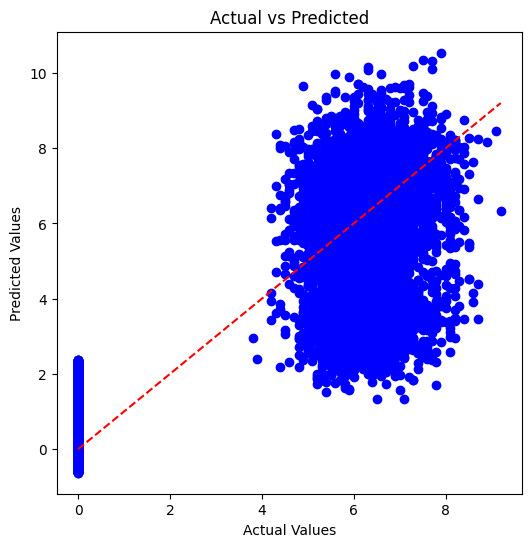

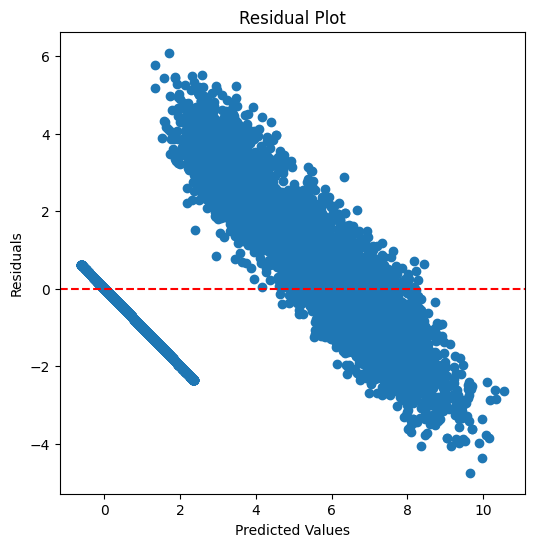

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import kagglehub

# Download the dataset
path = kagglehub.dataset_download(
    "rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset"
)

print("Dataset downloaded to:", path)

# Show the files inside the downloaded folder
print("\nFiles in dataset:")
print(os.listdir(path))

# Replace "filename.csv" with the actual CSV file name shown above
csv_file = os.path.join(path, "fifa_world_cup_2026_player_performance.csv")

# Read the dataset
data = pd.read_csv(csv_file)

# Display first few rows
print(data.head())

# Display column names
print("\nColumns:")
print(data.columns)

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Remove rows with missing values
data = data.dropna()

# ==========================
# SELECT FEATURES & TARGET
# Replace these with actual column names
# ==========================
# Features

//new code starts
X = data[[
    'goals',
    'assists',
    'shots_on_target',
    'pass_accuracy',
    'successful_passes',
    'tackles',
    'interceptions',
    'distance_covered_km',
    'stamina_score'
]]

# Target
y = data['player_rating']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Intercept:", model.intercept_)
print("\nCoefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.4f}")

print("\nMean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)


// new code ends


# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nResults")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

# Actual vs Predicted plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color="blue")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.show()

# Residual Plot
residuals = y_test - y_pred

plt.figure(figsize=(6,6))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()